In [1]:
import os
import sys
import pandas as pd
import numpy as np
import joblib
import yaml
import shap

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from shap_utils import compute_shap_values, get_top_features, plot_shap_summary, plot_shap_bar
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

SEED = config["seed"]
PROCESSED_DIR = os.path.join(PROJECT_ROOT, config["paths"]["processed_dir"])
MODELS_ROOT = os.path.join(PROJECT_ROOT, config["paths"]["models_dir"])
TABLES_DIR = os.path.join(PROJECT_ROOT, config["paths"]["tables_dir"])

print("shap version:", shap.__version__)

shap version: 0.51.0


In [2]:
def run_shap_analysis(dataset_tag, data_dir, models_dir, feature_cols, sample_size=500):
    test = pd.read_csv(os.path.join(data_dir, "test.csv"))
    pipeline = joblib.load(os.path.join(models_dir, "rf_pipeline.joblib"))

    shap_values, feature_names, X_transformed, X_sample = compute_shap_values(
        pipeline, test[feature_cols], sample_size=sample_size, seed=SEED)

    top_features = get_top_features(shap_values, feature_names, n=15)
    print(f"\n{'='*50}\n{dataset_tag} — Top 15 predictors by mean |SHAP|\n{'='*50}")
    print(top_features)

    top_features.to_csv(os.path.join(TABLES_DIR, f"{dataset_tag}_shap_top_features.csv"), index=False)

    plot_shap_bar(top_features, PROJECT_ROOT, dataset_tag, save_fig_fn=save_fig)
    plot_shap_summary(shap_values, X_transformed, feature_names, PROJECT_ROOT, dataset_tag, save_fig_fn=save_fig)

    return shap_values, feature_names, top_features


pakistan — Top 15 predictors by mean |SHAP|
                                          feature  mean_abs_shap
0          cat__Current Appereance Acceptance_Yes       0.014535
1           cat__Current Appereance Acceptance_No       0.013068
2   cat__Relationship with Mother in-law_Moderate       0.007388
3                    cat__Female Education_Matric       0.005436
4       cat__Relationship with Mother in-law_Good       0.005162
5                cat__Working Status_Working Lady       0.003684
6                  cat__Male Gender Preference_No       0.003398
7             cat__Husband Education_Intermediate       0.003227
8                 cat__Male Gender Preference_Yes       0.003130
9                   cat__Working Status_Housewife       0.003023
10               cat__Female Education_Uneducated       0.002733
11      cat__Sufficient Money for Basic Needs_Yes       0.002578
12                  cat__Husband Education_Matric       0.002298
13              cat__Husband Education_Uneduc

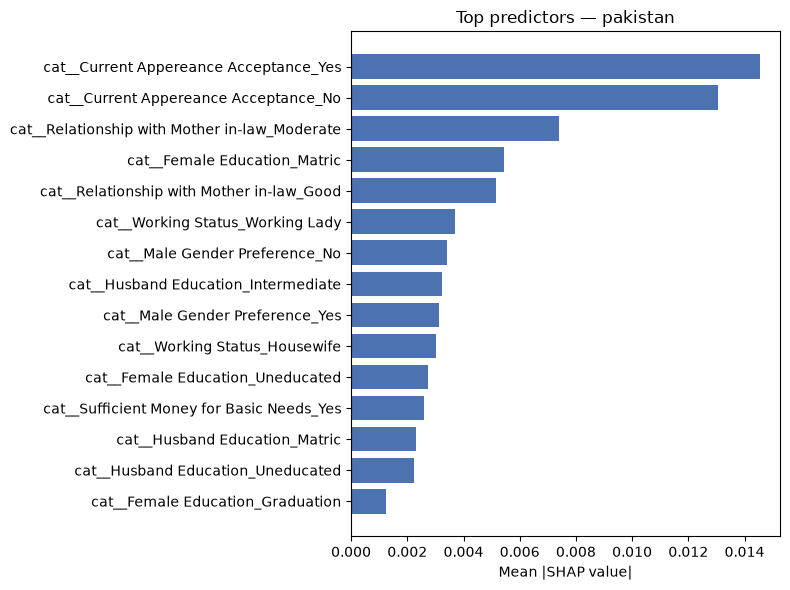

Saved figure: C:\maternal-mental-health-risk\reports\figures\pakistan\pakistan_shap_summary.png


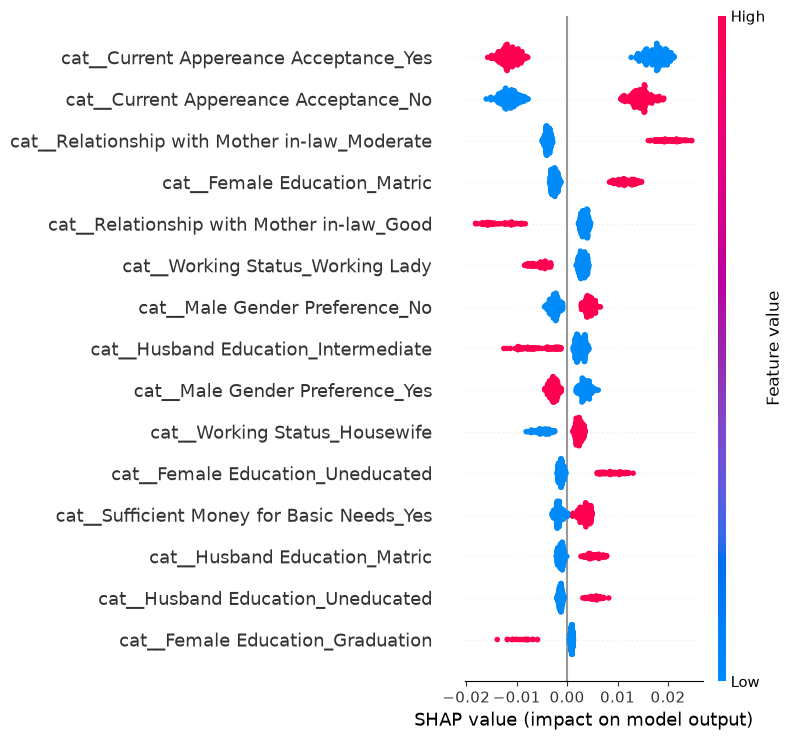

In [3]:
feature_cols_pk = ["Age", "Gestational Age", "Number of sons ", "Number of daughters",
                    "Total Number of Children", "Gravida", "Female Education", "Husband Education",
                    "Working Status", "Physical Health ", "Previous Miscarriage",
                    "Sufficient Money for Basic Needs", "Current Appereance Acceptance",
                    "Family System", "Male Gender Preference", "Relationship with Mother in-law"]

shap_pk, names_pk, top_pk = run_shap_analysis(
    "pakistan", os.path.join(PROCESSED_DIR, "pakistan"), os.path.join(MODELS_ROOT, "pakistan"), feature_cols_pk)


arab5_depression — Top 15 predictors by mean |SHAP|
                     feature  mean_abs_shap
0   cat__StressduringCovid_1       0.031608
1   cat__StressduringCovid_0       0.030501
2   cat__PsychologicalProb_1       0.029079
3   cat__PsychologicalProb_0       0.028722
4       cat__FamilyIncome1_1       0.019195
5       cat__FamilyIncome1_2       0.017937
6                cat__Work_1       0.011807
7                cat__Work_2       0.011713
8      cat__FamilyProblems_1       0.010240
9       cat__part1_country_2       0.010123
10     cat__FamilyProblems_0       0.009517
11        num__SleepingAfter       0.005426
12          num__CovidDiagL2       0.003948
13     cat__EducationLevel_2       0.003854
14      cat__part1_country_8       0.003758
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_depression\arab5_depression_shap_bar.png


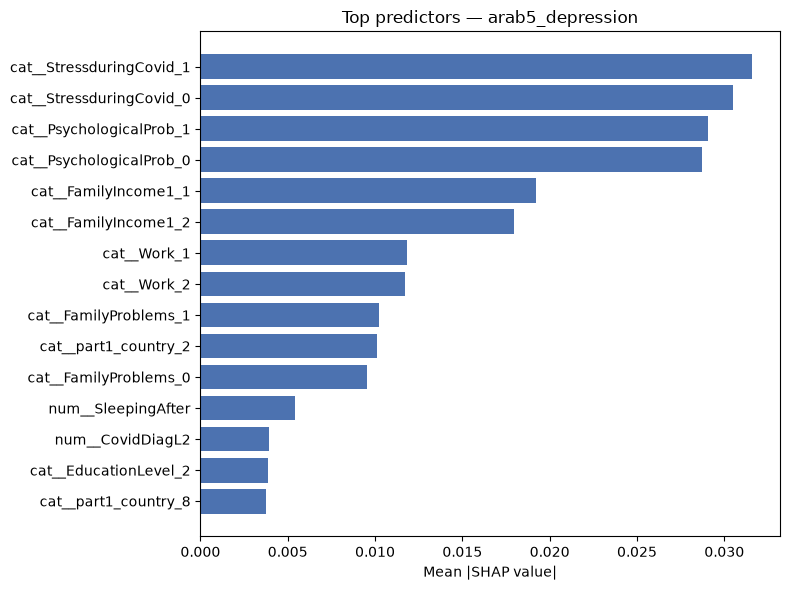

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_depression\arab5_depression_shap_summary.png


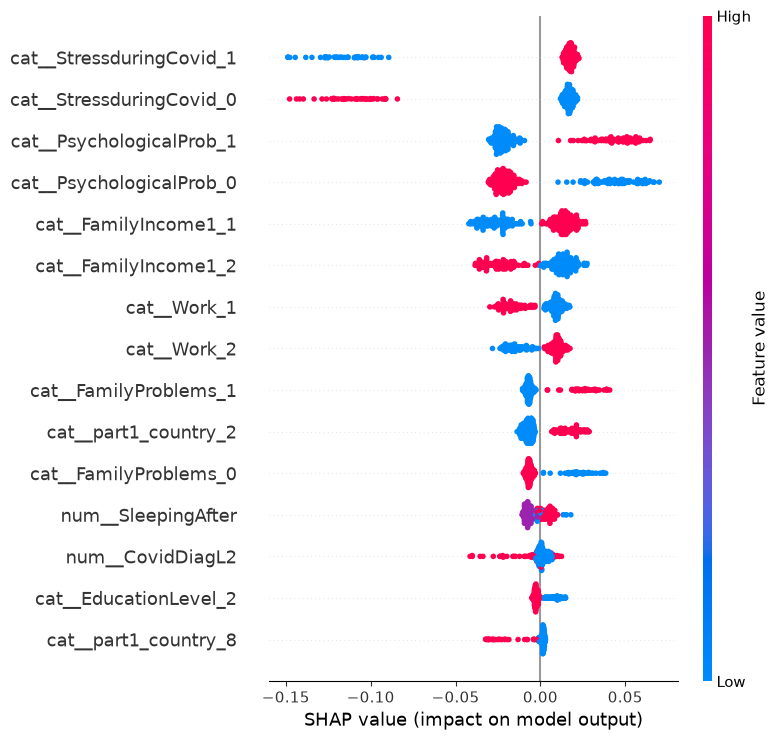

In [4]:
feature_cols_ar = ["part1_country", "Locality_first", "WomenAge", "MariageAge", "NumberofPregnancy",
                    "NumberofAbortions", "EducationLevel", "Work", "CovidDiagL1", "CovidDiagL2",
                    "Health_Prob", "StressduringCovid", "FamilyProblems", "FinancialProblem",
                    "SocialProblem", "PsychologicalProb", "WorkStress", "FamilyIncome1",
                    "SleepingAfter", "BMI_Pregnancy", "part1_current_preg_first"]

shap_ar_dep, names_ar_dep, top_ar_dep = run_shap_analysis(
    "arab5_depression", os.path.join(PROCESSED_DIR, "arab5_depression"),
    os.path.join(MODELS_ROOT, "arab5_depression"), feature_cols_ar)


arab5_anxiety — Top 15 predictors by mean |SHAP|
                     feature  mean_abs_shap
0   cat__StressduringCovid_1       0.064988
1   cat__StressduringCovid_0       0.056388
2       cat__FamilyIncome1_2       0.047553
3       cat__FamilyIncome1_1       0.042682
4   cat__PsychologicalProb_1       0.041075
5   cat__PsychologicalProb_0       0.038957
6       cat__part1_country_1       0.018454
7           num__CovidDiagL2       0.011689
8       cat__part1_country_8       0.009861
9    cat__FinancialProblem_0       0.009593
10     cat__FamilyProblems_1       0.007365
11        num__BMI_Pregnancy       0.007035
12   cat__FinancialProblem_1       0.006662
13     cat__FamilyProblems_0       0.006147
14         cat__WorkStress_0       0.006044
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_anxiety\arab5_anxiety_shap_bar.png


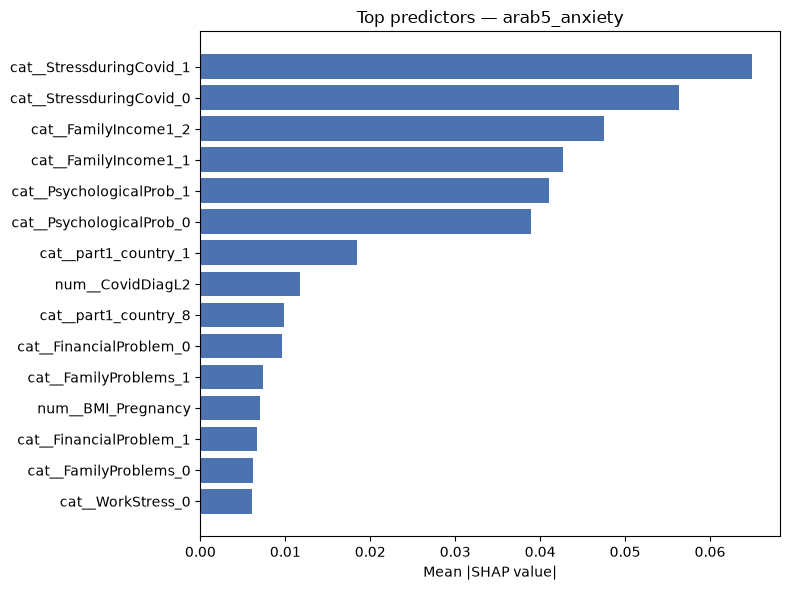

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_anxiety\arab5_anxiety_shap_summary.png


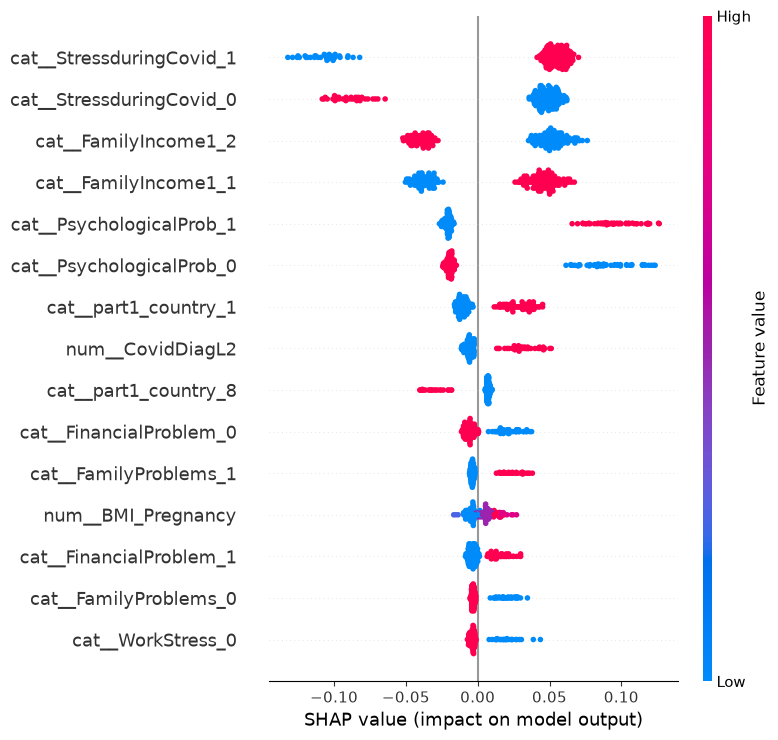

In [5]:
shap_ar_anx, names_ar_anx, top_ar_anx = run_shap_analysis(
    "arab5_anxiety", os.path.join(PROCESSED_DIR, "arab5_anxiety"),
    os.path.join(MODELS_ROOT, "arab5_anxiety"), feature_cols_ar)


uganda — Top 15 predictors by mean |SHAP|
                                          feature  mean_abs_shap
0   cat__spouseOccupation_informal business owner       0.035845
1                              num__otherChildren       0.028126
2                               num__numMissCarry       0.020150
3                cat__spouseOccupation_Unemployed       0.019996
4                                num__age_numeric       0.019121
5    cat__relationshipStatus_Traditional Marriage       0.019105
6     cat__spouseOccupation_formal business owner       0.017418
7                          cat__education_O-level       0.013627
8                  cat__relationshipStatus_Single       0.011575
9         cat__spouseOccupation_informal employee       0.010963
10                     cat__occupation_Unemployed       0.009785
11        cat__occupation_informal business owner       0.008986
12                      cat__homeDistrict_Kampala       0.008586
13                               cat__polygamy_

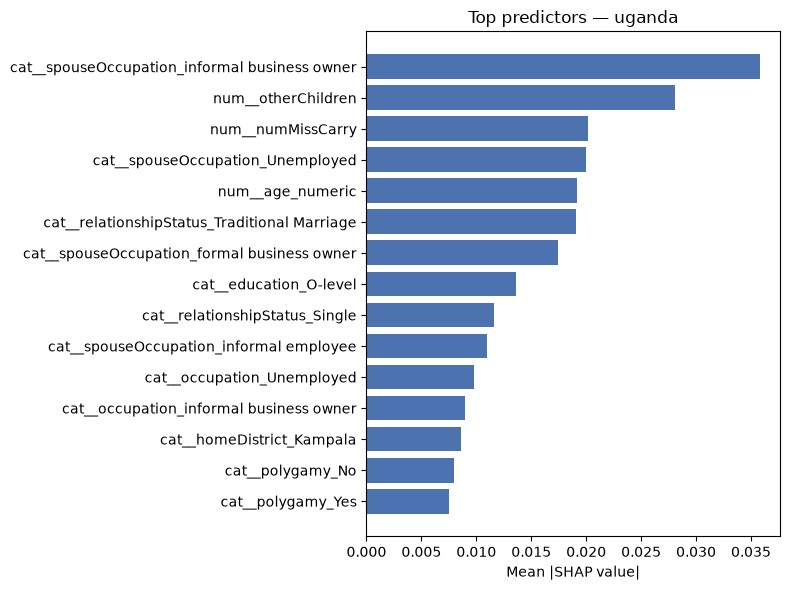

Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\uganda_shap_summary.png


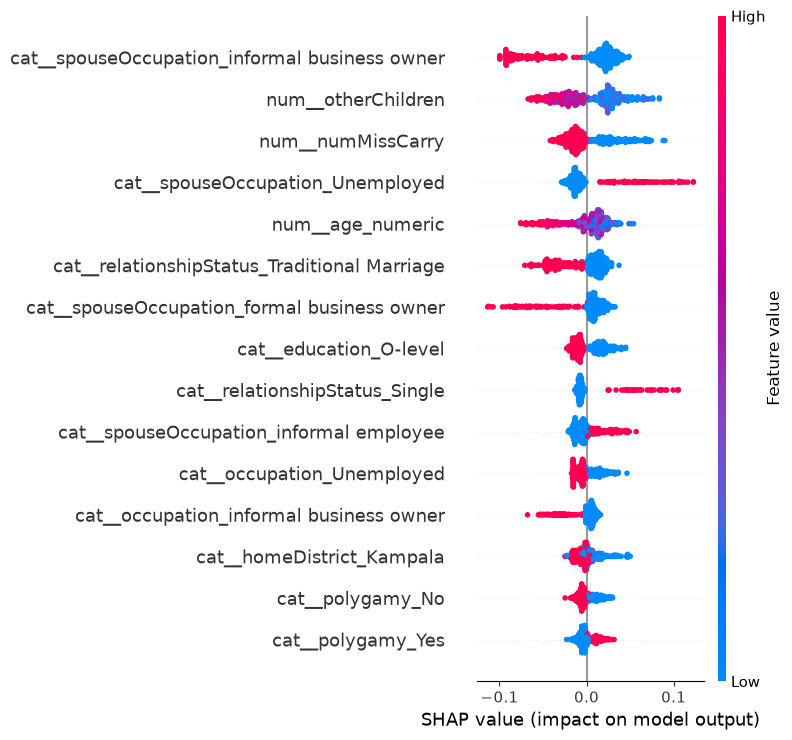

In [6]:
feature_cols_ug = ["age_numeric", "homeDistrict", "occupation", "relationshipStatus",
                    "spouseOccupation", "polygamy", "otherChildren", "numStillBorn",
                    "numMissCarry", "education"]

shap_ug, names_ug, top_ug = run_shap_analysis(
    "uganda", os.path.join(PROCESSED_DIR, "uganda"), os.path.join(MODELS_ROOT, "uganda"), feature_cols_ug)

In [7]:
all_top = {
    "pakistan": set(top_pk["feature"].str.replace("num__", "").str.replace("cat__", "").str.split("_").str[0]),
    "arab5_depression": set(top_ar_dep["feature"].str.replace("num__", "").str.replace("cat__", "").str.split("_").str[0]),
    "arab5_anxiety": set(top_ar_anx["feature"].str.replace("num__", "").str.replace("cat__", "").str.split("_").str[0]),
    "uganda": set(top_ug["feature"].str.replace("num__", "").str.replace("cat__", "").str.split("_").str[0]),
}
for tag, feats in all_top.items():
    print(f"{tag}: {sorted(feats)}")

pakistan: ['Age', 'Current Appereance Acceptance', 'Family System', 'Female Education', 'Husband Education', 'Male Gender Preference', 'Previous Miscarriage', 'Relationship with Mother in-law', 'Sufficient Money for Basic Needs']
arab5_depression: ['CovidDiagL2', 'EducationLevel', 'FamilyIncome1', 'FamilyProblems', 'PsychologicalProb', 'SleepingAfter', 'StressduringCovid', 'Work', 'part1']
arab5_anxiety: ['BMI', 'CovidDiagL2', 'FamilyIncome1', 'FamilyProblems', 'FinancialProblem', 'PsychologicalProb', 'StressduringCovid', 'WorkStress', 'part1']
uganda: ['age', 'education', 'homeDistrict', 'numMissCarry', 'occupation', 'otherChildren', 'polygamy', 'relationshipStatus', 'spouseOccupation']
